# Data VZP: segmentace pozvaných žen (alternativní finální verze)

Jedenáct akčních segmentů (`config/segments_vzp_v2.yaml`), jejich rozhodovací strom, predikce účasti
ze segmentů **naučená na letech 2020–2023 a ověřená na roce 2024**, přechody mezi segmenty
a návrhy experimentů. Shrnuje `vzp_segmentation.ipynb` (vývoj pravidel, v1 vs. v2)
a `vzp_segment_transitions.ipynb` (přechody).

**Čím se liší od `vzp_segmentation_final.ipynb`** (hlavní verze, podklad pro `docs/vzp_segmentace/slides.md`):

* **model hazardu** pro srovnání se učí do června 2023 s **early stoppingem na 2. pololetí 2023**
  (místo pevných 750 iterací na všech pozvánkách 2020–2023);
* **zjednodušený graf přechodů** slučuje 11 segmentů do **šesti skupin** podle významu pro VZP
  (místo zúžení na pět největších segmentů);
* **experimenty E1–E7** jsou navržené přes **potřebný počet žen na rameno** pro zadaný účinek
  (MDE = spodní hranice očekávaného přínosu z `docs/interventions.md`), s design efektem 2
  pro randomizaci po ordinacích gynekologů (místo nejmenšího zjistitelného účinku pro danou velikost).

Data: 1 344 556 adresných pozvánek 2020–2024 pro 508 527 žen pojištěných u VZP nepřetržitě
2015–2025 (`data_vzp/Rakhaton2026.csv.gz`). Notebook ukazuje jen agregáty.

In [1]:
import textwrap
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from catboost import CatBoostClassifier, Pool
from matplotlib import colormaps
from matplotlib.patches import FancyBboxPatch
from scipy.stats import norm
from sklearn.metrics import log_loss, roc_auc_score

warnings.filterwarnings("ignore")
BASE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_vzp").exists())
OUT = BASE / "outputs" / "vzp_segmentation_final_alt"
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 100)

LABELS = ["SCREENING_3M_FLAG", "SCREENING_6M_FLAG", "SCREENING_12M_FLAG"]
HOR = ["3M", "6M", "12M"]
Y12 = LABELS[2]
AN = ["FIRST_INVITATION", "GP_REGISTERED", "GYN_REGISTERED_FLAG", "NEVER_SCREENED_BEFORE_FLAG"] + LABELS
BANDS = ["AGE_BAND", "GP_REG_DURATION_BAND", "GYN_REG_DURATION_BAND"]
REG = {"<2": 1, "2-5": 2, ">5": 3}
CAT = ["VZP_TERRITORIAL_AREA"]

d = pd.read_csv(BASE / "data_vzp" / "Rakhaton2026.csv.gz", low_memory=False)
d["INVITATION_DATE"] = pd.to_datetime(d.INVITATION_DATE, format="%d.%m.%Y")
for c in AN:
    d[c] = (d[c] == "A").astype(int)
d["AGE_BAND"] = d.AGE_BAND.str[:2].astype(int)
for c in BANDS[1:]:
    d[c] = d[c].map(REG).fillna(0).astype(int)
assert ((d[LABELS[0]] <= d[LABELS[1]]) & (d[LABELS[1]] <= d[LABELS[2]])).all()
d["UDALOST"] = 4 - d[LABELS].sum(axis=1)
FEATURES = [c for c in d.columns if c not in LABELS + ["INVITATION_ID", "PERSON_ID", "INVITATION_DATE", "UDALOST"]]

d["BEZ_SCREENINGU"] = d.MONTHS_SINCE_LAST_SCREEN.isna().astype(int)
d["PREVENCE"] = ((d.OTHER_SCREENING_36M_CNT >= 1) | (d.DENTAL_PREVENTION_24M_CNT >= 1)
                 | (d.GP_PREVENTION_24M_CNT >= 1)).astype(int)

SEG = yaml.safe_load(open(BASE / "config" / "segments_vzp_v2.yaml", encoding="utf-8"))["segments"]
NAZEV = {s["id"]: s["name_cs"] for s in SEG}
PORADI = [s["id"] for s in SEG]
NAZVY = [NAZEV[s] for s in PORADI]

def prirad(df):
    """Segment podle pravidel: první pravidlo, které platí."""
    out = pd.Series(pd.NA, index=df.index, dtype="object")
    for s in SEG:
        m = df.eval(s["rule"])
        if np.isscalar(m):
            m = pd.Series(bool(m), index=df.index)
        out[out.isna() & m.astype(bool)] = s["id"]
    assert out.notna().all()
    return out

d["SEG"] = prirad(d)
d["SEGMENT"] = d.SEG.map(NAZEV)
UC = (d.INVITATION_DATE < "2024-01-01").values      # "učení" segmentového modelu: 2020–2023
test = d[~UC].copy()                                 # test: 2024 (každá žena právě jedna pozvánka)
print(f"{len(d):,} pozvánek · {d.PERSON_ID.nunique():,} žen · {len(SEG)} segmentů · "
      f"učení 2020–2023: {UC.sum():,} · test 2024: {len(test):,} pozvánek ({test.PERSON_ID.nunique():,} žen)")

1,344,556 pozvánek · 508,527 žen · 11 segmentů · učení 2020–2023: 1,088,090 · test 2024: 256,466 pozvánek (256,466 žen)


## 1 · Segmentační model

Segmentační „model“ je pevný seznam pravidel. Pozvánka patří do **prvního** segmentu, jehož pravidlo
platí (pořadí je priorita). Odvozené sloupce: `BEZ_SCREENINGU` = žádný kód screeningu za 5 let,
`PREVENCE` = zubní prevence, preventivní prohlídka u praktika nebo jiný screening. Predikcí segmentu
je jeho účast v letech 2020–2023; nic jiného se neučí.

In [2]:
g = d[UC].groupby("SEG")
PRAV = pd.DataFrame({
    "segment": NAZVY,
    "pravidlo": [s["rule"] for s in SEG],
    "pozvánek 2020–2023": g.size().reindex(PORADI).values,
    "účast 12M 2020–2023": g[Y12].mean().reindex(PORADI).values,
    "žen 2024": test.groupby("SEG").size().reindex(PORADI).values,
    "páky (hypotéza)": [s["levers_cs"] for s in SEG],
}, index=range(1, len(SEG) + 1))
PRAV.to_csv(OUT / "segmenty_pravidla.csv")
PRAV.style.format({"pozvánek 2020–2023": "{:,}", "žen 2024": "{:,}", "účast 12M 2020–2023": "{:.1%}"})

,segment,pravidlo,pozvánek 2020–2023,účast 12M 2020–2023,žen 2024,páky (hypotéza)
1,Dopis se minul se screeningem,MONTHS_SINCE_LAST_SCREEN < 24,"28,890",2.4%,"7,600","Žádná intervence; opravit zvaní (ověřit vykázání těsně před odesláním, odklad 1–2 měsíce)."
2,"První pozvánka, málo kontaktů",FIRST_INVITATION == 1 and HEALTHCARE_CONTACT_12M_CNT < 6,"29,511",30.6%,"7,127","Osobnější první kontakt (SMS, telefon, praktik), jednoduché vysvětlení, snadné objednání."
3,"První pozvánka, v kontaktu",FIRST_INVITATION == 1,"151,206",56.9%,"30,333","Informace pro ženy, které jdou poprvé, načasování k narozeninám, sociální norma, snadné objednání."
4,Vypadlá z návyku (3–4 roky),MONTHS_SINCE_LAST_SCREEN <= 48,"73,464",34.2%,"16,167","Připomínka s jednoduchým objednáním, plán kdy a kde (implementation intention)."
5,Vypadlá z návyku (4–5+ let),MONTHS_SINCE_LAST_SCREEN > 48,"60,862",24.8%,"12,410","Osobnější připomínka (SMS, telefon), doporučení gynekologa."
6,"Bez screeningu, gynekolog, zvaná málokrát",BEZ_SCREENINGU == 1 and GYN_PREVENTION_24M_CNT >= 1 and PRIOR_INVITATION_COUNT <= 6,"134,340",26.3%,"31,098","Připomínka s odkazem na gynekologa, žádanka při nejbližší prohlídce."
7,"Bez screeningu, gynekolog, opakovaně nereaguje",BEZ_SCREENINGU == 1 and GYN_PREVENTION_24M_CNT >= 1,"55,462",9.0%,"19,949",Dopisy nefungují: aktivní role gynekologa (objednání přímo při prohlídce).
8,"Bez screeningu, jiná prevence, zvaná málokrát",BEZ_SCREENINGU == 1 and PREVENCE == 1 and PRIOR_INVITATION_COUNT <= 6,"154,935",11.8%,"29,487","Připomínka se sociální normou, propojení s jinou prevencí (praktik, zubař), pohodlné termíny."
9,"Bez screeningu, jiná prevence, opakovaně nereaguje",BEZ_SCREENINGU == 1 and PREVENCE == 1 and PRIOR_INVITATION_COUNT >= 7,"216,573",3.9%,"59,864","Dopisy nefungují: jiný kanál (praktik, osobní kontakt), informované rozhodnutí."
10,"Bez screeningu a prevence, v kontaktu se zdravotnictvím",BEZ_SCREENINGU == 1 and HEALTHCARE_CONTACT_12M_CNT >= 6,"84,908",5.0%,"18,102","Oportunisticky přes ošetřující lékaře (praktik, specialisté)."


## 2 · Rozhodovací strom segmentů

Stejná pravidla nakreslená jako strom otázek (v notebooku ověřeno, že strom přiřadí každou pozvánku
do stejného segmentu jako pravidla). U otázek je počet pozvánek 2020–2023, které k ní dojdou; u listů
počet žen v roce 2024 a účast do 12 měsíců v letech 2020–2023. Barva listu = účast.

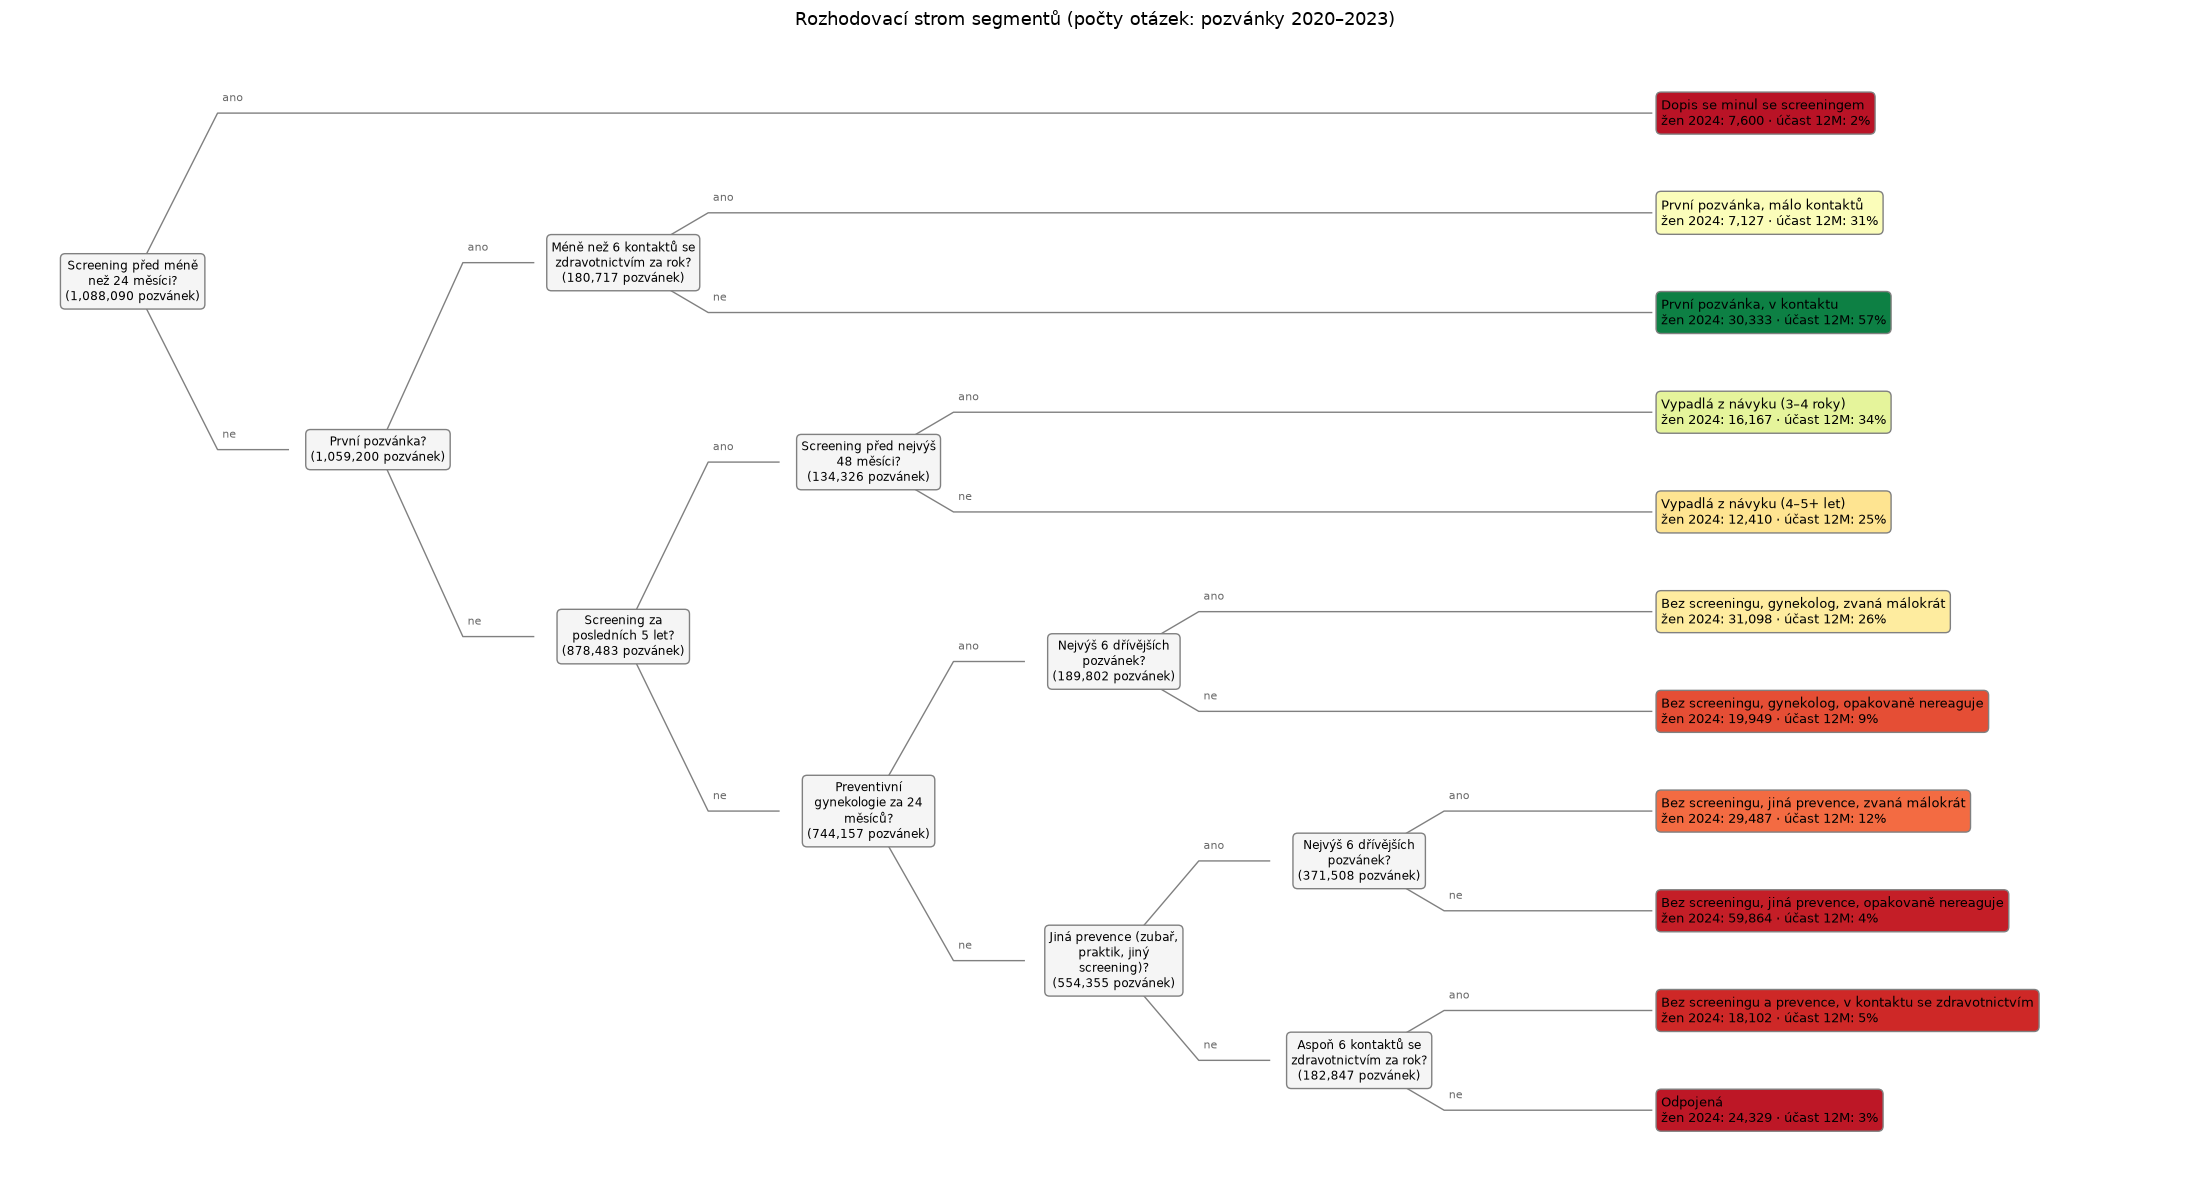

In [3]:
# strom: (otázka, test, větev ano, větev ne); list = id segmentu
STROM = ("Screening před méně než 24 měsíci?", lambda x: x.MONTHS_SINCE_LAST_SCREEN < 24, "minula_se",
         ("První pozvánka?", lambda x: x.FIRST_INVITATION == 1,
          ("Méně než 6 kontaktů se zdravotnictvím za rok?", lambda x: x.HEALTHCARE_CONTACT_12M_CNT < 6,
           "prvni_pozvanka_malo_kontaktu", "prvni_pozvanka"),
          ("Screening za posledních 5 let?", lambda x: x.BEZ_SCREENINGU == 0,
           ("Screening před nejvýš 48 měsíci?", lambda x: x.MONTHS_SINCE_LAST_SCREEN <= 48, "vypadla_3_4", "vypadla_4_plus"),
           ("Preventivní gynekologie za 24 měsíců?", lambda x: x.GYN_PREVENTION_24M_CNT >= 1,
            ("Nejvýš 6 dřívějších pozvánek?", lambda x: x.PRIOR_INVITATION_COUNT <= 6,
             "nikdy_gynekolog_malo_zvana", "nikdy_gynekolog_nereaguje"),
            ("Jiná prevence (zubař, praktik, jiný screening)?", lambda x: x.PREVENCE == 1,
             ("Nejvýš 6 dřívějších pozvánek?", lambda x: x.PRIOR_INVITATION_COUNT <= 6,
              "nikdy_prevence_malo_zvana", "nikdy_prevence_nereaguje"),
             ("Aspoň 6 kontaktů se zdravotnictvím za rok?", lambda x: x.HEALTHCARE_CONTACT_12M_CNT >= 6,
              "nikdy_kontakt", "odpojena"))))))

def strom_prirad(df, uzel=STROM):
    if isinstance(uzel, str):
        return pd.Series(uzel, index=df.index)
    _, test_fn, ano, ne = uzel
    m = test_fn(df).astype(bool)
    return pd.concat([strom_prirad(df[m], ano), strom_prirad(df[~m], ne)])

assert strom_prirad(d).reindex(d.index).eq(d.SEG).all(), "strom se neshoduje s pravidly"

# rozložení: kořen vlevo, listy v jednom sloupci vpravo
UZLY, HRANY, citac = [], [], [0]
def rozloz(uzel, hloubka, df):
    i = len(UZLY); UZLY.append(None)
    if isinstance(uzel, str):
        y = citac[0]; citac[0] += 1
        UZLY[i] = dict(x=None, y=y, list=True, seg=uzel)
        return i, y
    otazka, test_fn, ano, ne = uzel
    m = test_fn(df).astype(bool)
    ia, ya = rozloz(ano, hloubka + 1, df[m])
    ine, yn = rozloz(ne, hloubka + 1, df[~m])
    y = (ya + yn) / 2
    UZLY[i] = dict(x=hloubka, y=y, list=False, text=otazka, n=len(df))
    HRANY.extend([(i, ia, "ano"), (i, ine, "ne")])
    return i, y

rozloz(STROM, 0, d[UC])
DX, LIST_X = 2.6, 6 * 2.6 + 0.6
u12 = d[UC].groupby("SEG")[Y12].mean()
n24 = test.groupby("SEG").size()
cmap = colormaps["RdYlGn"]

fig, ax = plt.subplots(figsize=(22, 12))
for u in UZLY:
    u["px"] = LIST_X if u["list"] else u["x"] * DX
    u["py"] = -u["y"]
for a, b, lab in HRANY:
    A, B = UZLY[a], UZLY[b]
    ax.plot([A["px"], A["px"] + 0.9, B["px"] - (0.1 if B["list"] else 0.95)], [A["py"], B["py"], B["py"]],
            color="gray", lw=1, zorder=1)
    ax.text(A["px"] + 0.95, B["py"] + 0.12, lab, fontsize=8, color="dimgray")
for u in UZLY:
    if u["list"]:
        s = u["seg"]
        txt = f"{NAZEV[s]}\nžen 2024: {n24.get(s, 0):,} · účast 12M: {u12[s]:.0%}"
        ax.text(u["px"], u["py"], txt, ha="left", va="center", fontsize=9, zorder=3,
                bbox=dict(boxstyle="round,pad=0.4", fc=cmap(min(u12[s] / 0.6, 1)), ec="gray"))
    else:
        txt = textwrap.fill(u["text"], 22) + f"\n({u['n']:,} pozvánek)"
        ax.text(u["px"], u["py"], txt, ha="center", va="center", fontsize=8.5, zorder=3,
                bbox=dict(boxstyle="round,pad=0.4", fc="whitesmoke", ec="gray"))
ax.set_xlim(-1.3, LIST_X + 5.5); ax.set_ylim(-len(SEG) + 0.3, 0.8); ax.axis("off")
ax.set_title("Rozhodovací strom segmentů (počty otázek: pozvánky 2020–2023)", fontsize=13)
plt.tight_layout(); plt.savefig(OUT / "rozhodovaci_strom.png", dpi=120); plt.show()

**Jak číst.** Otázky se kladou zleva doprava, horní větev je „ano“. Číslo v otázce je počet pozvánek
2020–2023, které k ní dojdou. List ukazuje počet žen v roce 2024 a účast do 12 měsíců v letech
2020–2023; barva odpovídá účasti (zelená = chodí).

## 3 · Predikce ze segmentů: naučeno na 2020–2023, ověřeno na 2024

**Segmentový model**: každá žena v roce 2024 dostane jako predikci účast svého segmentu v letech
2020–2023 (pro 3, 6 a 12 měsíců). **Model hazardu** (CatBoost, 19 sloupců, učení do června 2023,
early stopping na 2. pololetí 2023, viz `vzp_hazard.ipynb`) slouží jako srovnání a ukazuje rozptyl
rizika uvnitř segmentů. Rok 2024 do učení nevstupuje u žádného z nich.

In [4]:
SAZBY = d[UC].groupby("SEG")[LABELS].mean()
for h, y in zip(HOR, LABELS):
    test[f"s_{h}"] = test.SEG.map(SAZBY[y])

FS = FEATURES + ["INTERVAL"]
def roztahni(df):
    parts = []
    for k in (1, 2, 3):
        r = df.UDALOST >= k
        parts.append(df.loc[r, FEATURES].assign(INTERVAL=k, y=(df.UDALOST[r] == k).astype(int)))
    return pd.concat(parts)
tr = roztahni(d[d.INVITATION_DATE < "2023-07-01"])
va = roztahni(d[UC & (d.INVITATION_DATE >= "2023-07-01").values])
MH = CatBoostClassifier(iterations=3000, learning_rate=0.1, depth=6, eval_metric="Logloss",
                        od_type="Iter", od_wait=100, thread_count=-1, random_seed=0, verbose=0)
MH.fit(Pool(tr[FS], tr.y, cat_features=CAT), eval_set=Pool(va[FS], va.y, cat_features=CAT))
H = np.column_stack([MH.predict_proba(Pool(test[FEATURES].assign(INTERVAL=k), cat_features=CAT))[:, 1] for k in (1, 2, 3)])
F = 1 - np.cumprod(1 - H, axis=1)
for j, h in enumerate(HOR):
    test[f"p_{h}"] = F[:, j]

CELK = pd.DataFrame([{"horizont": h, "účast 2024": test[y].mean(),
                      "segmenty: průměr predikce": test[f"s_{h}"].mean(),
                      "segmenty: AUROC": roc_auc_score(test[y], test[f"s_{h}"]),
                      "segmenty: log-loss": log_loss(test[y], test[f"s_{h}"]),
                      "model hazardu: průměr predikce": test[f"p_{h}"].mean(),
                      "model hazardu: AUROC": roc_auc_score(test[y], test[f"p_{h}"]),
                      "model hazardu: log-loss": log_loss(test[y], test[f"p_{h}"])}
                     for h, y in zip(HOR, LABELS)]).set_index("horizont")
CELK.to_csv(OUT / "predikce_celkem.csv")

rows = []
for s in PORADI:
    g = test[test.SEG == s]
    r = {"segment": NAZEV[s], "žen 2024": len(g)}
    for h, y in zip(HOR, LABELS):
        r[f"účast {h} 2024"] = g[y].mean()
        r[f"predikce {h} (2020–23)"] = g[f"s_{h}"].iloc[0]
    r["AUROC 12M uvnitř (model)"] = roc_auc_score(g[Y12], g.p_12M)
    r["model 12M p10"], r["model 12M p90"] = g.p_12M.quantile([0.1, 0.9]).values
    r["nepřišlo do 12M"] = int(len(g) - g[Y12].sum())
    rows.append(r)
S24 = pd.DataFrame(rows).set_index("segment")
S24.to_csv(OUT / "segmenty_2024.csv")
print(f"iterací modelu hazardu: {MH.get_best_iteration()}")
display(CELK.round(4))
S24.style.format({"žen 2024": "{:,}", "nepřišlo do 12M": "{:,}", "AUROC 12M uvnitř (model)": "{:.3f}",
                  **{c: "{:.1%}" for c in S24.columns if c.startswith(("účast", "predikce", "model 12M"))}})

iterací modelu hazardu: 750


,účast 2024,segmenty: průměr predikce,segmenty: AUROC,segmenty: log-loss,model hazardu: průměr predikce,model hazardu: AUROC,model hazardu: log-loss
horizont,,,,,,,
3M,0.0709,0.0653,0.8007,0.2144,0.0682,0.8350,0.2027
6M,0.1241,0.1153,0.8055,0.3042,0.1187,0.8356,0.2873
12M,0.1921,0.1780,0.8072,0.3871,0.1847,0.8362,0.3630


,žen 2024,účast 3M 2024,predikce 3M (2020–23),účast 6M 2024,predikce 6M (2020–23),účast 12M 2024,predikce 12M (2020–23),AUROC 12M uvnitř (model),model 12M p10,model 12M p90,nepřišlo do 12M
segment,,,,,,,,,,,
Dopis se minul se screeningem,"7,600",1.5%,1.3%,2.2%,2.0%,2.4%,2.4%,0.658,0.9%,5.1%,"7,418"
"První pozvánka, málo kontaktů","7,127",12.1%,10.5%,22.9%,19.8%,35.7%,30.6%,0.790,6.4%,64.0%,"4,580"
"První pozvánka, v kontaktu","30,333",25.2%,24.3%,42.0%,40.5%,59.6%,56.9%,0.702,32.3%,78.1%,"12,240"
Vypadlá z návyku (3–4 roky),"16,167",14.4%,12.2%,25.4%,22.0%,38.8%,34.2%,0.657,15.0%,54.5%,"9,892"
Vypadlá z návyku (4–5+ let),"12,410",8.8%,8.5%,15.8%,15.3%,25.7%,24.8%,0.632,11.9%,39.2%,"9,219"
"Bez screeningu, gynekolog, zvaná málokrát","31,098",10.6%,9.9%,17.6%,16.9%,27.1%,26.3%,0.661,14.3%,46.8%,"22,679"
"Bez screeningu, gynekolog, opakovaně nereaguje","19,949",3.8%,3.2%,6.4%,5.5%,10.3%,9.0%,0.606,5.5%,13.8%,"17,894"
"Bez screeningu, jiná prevence, zvaná málokrát","29,487",3.3%,3.0%,7.0%,6.5%,12.7%,11.8%,0.631,6.1%,19.5%,"25,734"
"Bez screeningu, jiná prevence, opakovaně nereaguje","59,864",1.3%,1.0%,2.7%,2.0%,5.1%,3.9%,0.639,2.1%,7.0%,"56,825"


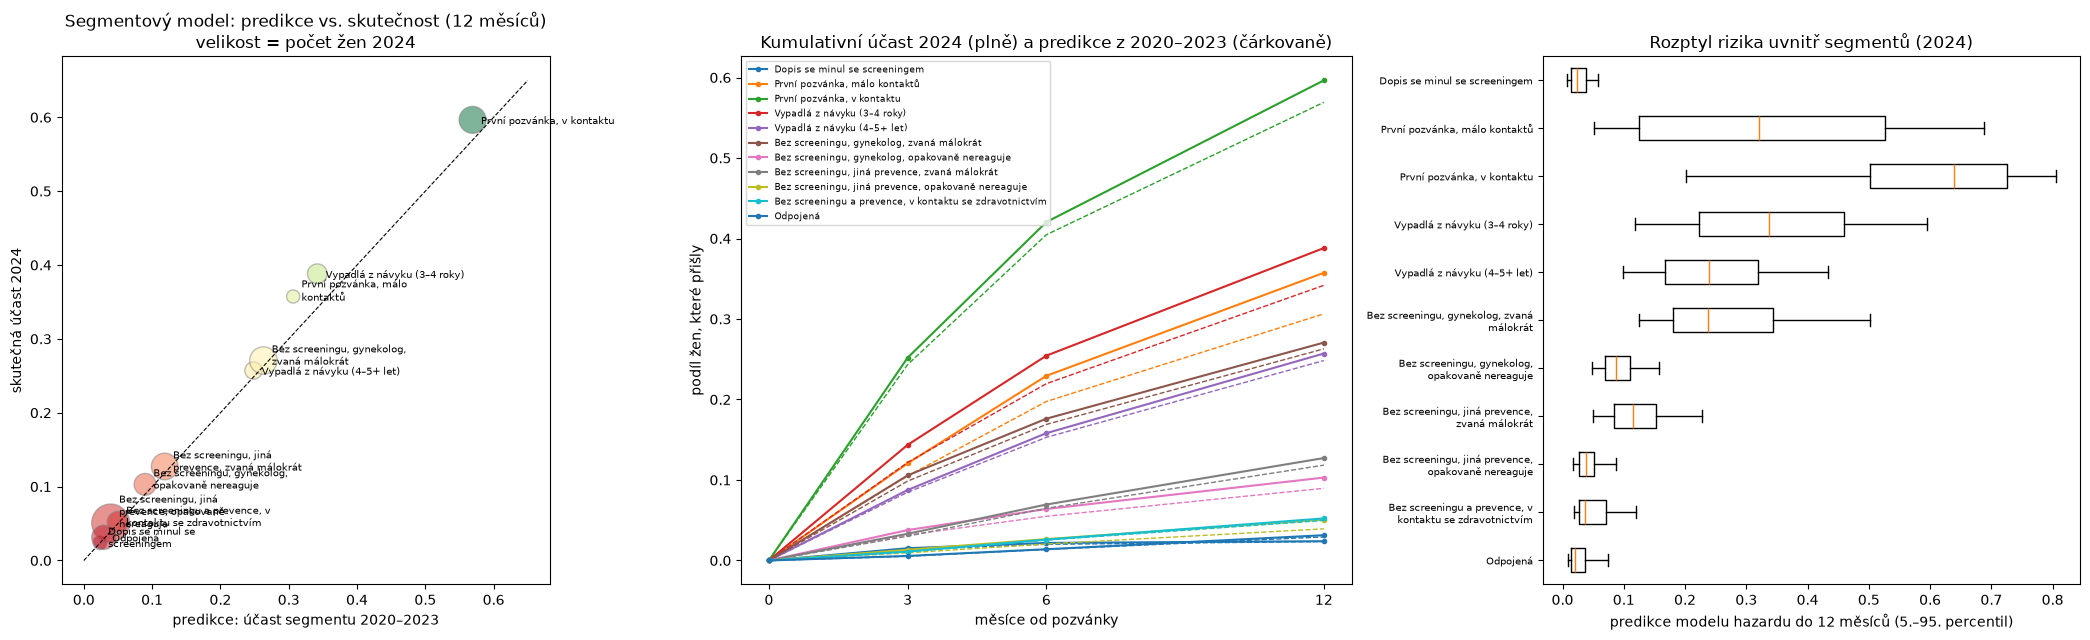

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6.5), gridspec_kw={"width_ratios": [1, 1.25, 1.1]})

ax = axes[0]   # kalibrace segmentového modelu: predikce 2020–23 vs skutečnost 2024
ax.scatter(S24["predikce 12M (2020–23)"], S24["účast 12M 2024"], s=S24["žen 2024"] / 80, alpha=0.5,
           c=[cmap(min(v / 0.6, 1)) for v in S24["účast 12M 2024"]], edgecolor="gray")
for n, r in S24.iterrows():
    ax.annotate(textwrap.fill(n, 28), (r["predikce 12M (2020–23)"], r["účast 12M 2024"]), fontsize=7,
                xytext=(6, -3), textcoords="offset points")
ax.plot([0, 0.65], [0, 0.65], "k--", lw=0.8)
ax.set_xlabel("predikce: účast segmentu 2020–2023"); ax.set_ylabel("skutečná účast 2024")
ax.set_title("Segmentový model: predikce vs. skutečnost (12 měsíců)\nvelikost = počet žen 2024")

ax = axes[1]   # kumulativní účast: skutečnost 2024 vs segmentový model
for i, s in enumerate(PORADI):
    g = test[test.SEG == s]
    ax.plot([0, 3, 6, 12], [0, *g[LABELS].mean()], "-o", ms=3, color=f"C{i % 10}", label=NAZEV[s])
    ax.plot([0, 3, 6, 12], [0, *SAZBY.loc[s]], "--", color=f"C{i % 10}", lw=1)
ax.set_xticks([0, 3, 6, 12]); ax.set_xlabel("měsíce od pozvánky"); ax.set_ylabel("podíl žen, které přišly")
ax.set_title("Kumulativní účast 2024 (plně) a predikce z 2020–2023 (čárkovaně)")
ax.legend(fontsize=6.5, loc="upper left")

ax = axes[2]   # rozptyl rizika uvnitř segmentů podle modelu hazardu
data = [test.loc[test.SEG == s, "p_12M"].values for s in PORADI]
ax.boxplot(data, orientation="horizontal", showfliers=False, whis=(5, 95))
ax.set_yticks(range(1, len(PORADI) + 1), [textwrap.fill(n, 34) for n in NAZVY], fontsize=7)
ax.invert_yaxis(); ax.set_xlabel("predikce modelu hazardu do 12 měsíců (5.–95. percentil)")
ax.set_title("Rozptyl rizika uvnitř segmentů (2024)")
plt.tight_layout(); plt.savefig(OUT / "predikce_2024.png", dpi=120); plt.show()

**Jak číst.** Vlevo: každý bod je segment, vodorovně předpověď z let 2020–2023, svisle skutečnost 2024
(čárkovaně shoda). Body leží těsně u diagonály; výrazně nad ní jsou jen první pozvánky a vypadlé 3–4 roky (účast roste).
Uprostřed: kumulativní účast 2024 (plně) a předpověď (čárkovaně) pro 3, 6 a 12 měsíců; pořadí segmentů
se nemění. Vpravo: rozptyl predikce modelu hazardu uvnitř segmentů (vousy 5.–95. percentil).

## 4 · Přechodová matice segmentů (pozvánky 2020–2023)

Po pozvánce nastane jedno ze tří: žena **přijde do 12 měsíců**, **nepřijde a dostane další pozvánku**
(zhruba za rok; sloupec = segment té další pozvánky), nebo **nepřijde a další pozvánku v datech nemá**.
Ženy, které přijdou, dostanou další dopis až po 3 a více letech, většinou mimo data. Řádky dávají 100 %.
Pozvánky z roku 2024 nemají pozorovatelné pokračování, proto jen 2020–2023.

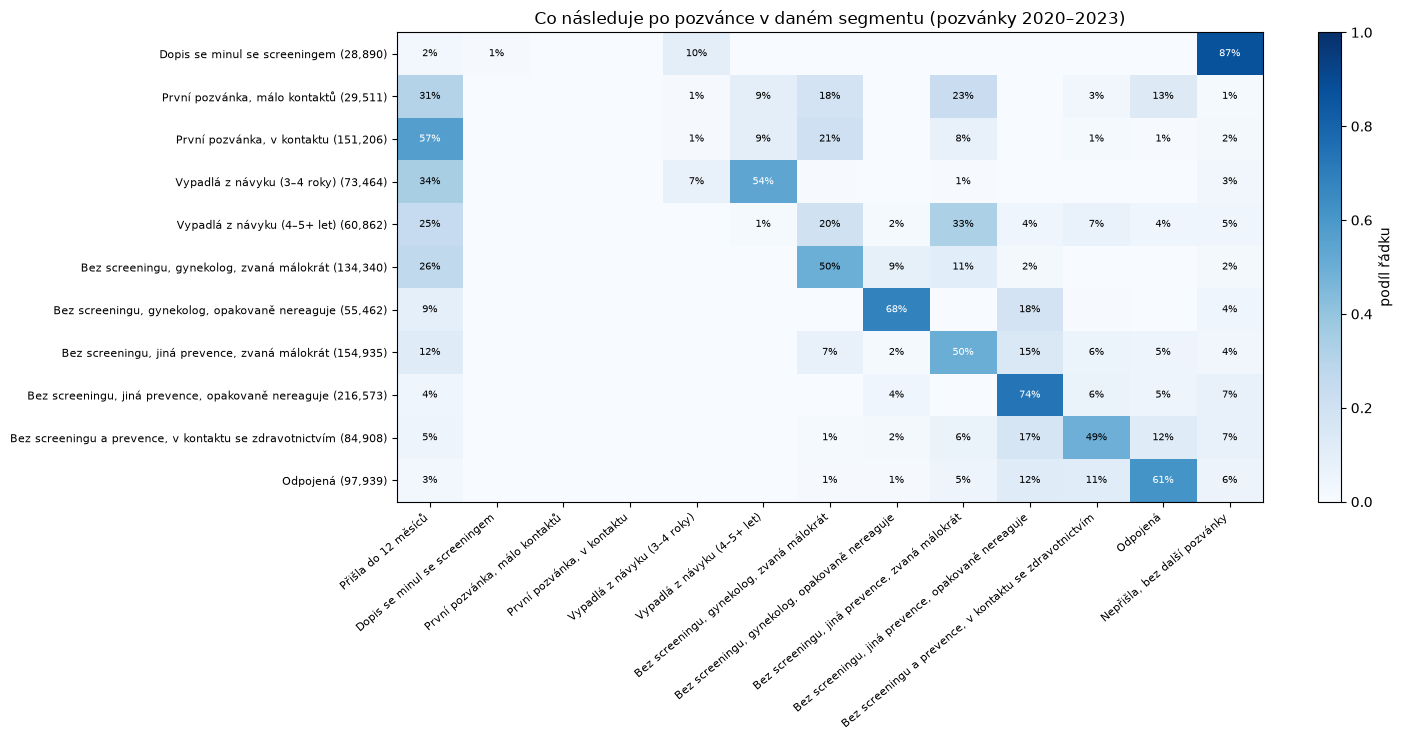

In [6]:
d = d.sort_values(["PERSON_ID", "INVITATION_DATE"])
d["SEG_DALSI"] = d.groupby("PERSON_ID").SEGMENT.shift(-1)
d = d.sort_index()
r = d[UC]
PRISLA, KONEC = "Přišla do 12 měsíců", "Nepřišla, bez další pozvánky"
dale = np.where(r[Y12] == 1, PRISLA, np.where(r.SEG_DALSI.notna(), r.SEG_DALSI, KONEC))
SLOUPCE = [PRISLA] + NAZVY + [KONEC]
CNT = pd.crosstab(r.SEGMENT, dale).reindex(index=NAZVY, columns=SLOUPCE, fill_value=0)
MAT = CNT.div(CNT.sum(axis=1), axis=0)
CNT.to_csv(OUT / "prechody_pocty.csv"); MAT.round(4).to_csv(OUT / "prechody_podily.csv")

fig, ax = plt.subplots(figsize=(15, 7.5))
im = ax.imshow(MAT.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(SLOUPCE))); ax.set_xticklabels(SLOUPCE, rotation=40, ha="right", fontsize=8)
ax.set_yticks(range(len(NAZVY))); ax.set_yticklabels([f"{n} ({CNT.loc[n].sum():,})" for n in NAZVY], fontsize=8)
for i in range(MAT.shape[0]):
    for j in range(MAT.shape[1]):
        v = MAT.iat[i, j]
        if v >= 0.005:
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7, color="white" if v > 0.5 else "black")
plt.colorbar(im, ax=ax, label="podíl řádku")
ax.set_title("Co následuje po pozvánce v daném segmentu (pozvánky 2020–2023)")
plt.tight_layout(); plt.savefig(OUT / "prechodova_matice.png", dpi=120); plt.show()

**Proč jsou některé sloupce prázdné.** Nejde o chybu, ale o definice segmentů:
* **„První pozvánka“ (oba sloupce) je prázdná z definice**: další pozvánka nikdy není první.
* **„Dopis se minul se screeningem“ je skoro prázdný**: vyžaduje screening 0–1 měsíc před dopisem,
  což se u ženy, která rok nepřišla, téměř nestane.
* **„Vypadlá z návyku (3–4 roky)“ je řídký**: vyžaduje screening před 36–48 měsíci, tedy ženu, která
  kdysi přišla; takové ženy jsou ale ve sloupci „přišla“ a další dopis dostanou až po 3 letech.

## 5 · Graf přechodů

Uzly jsou segmenty, šipky přechody k další pozvánce (podíl všech pozvánek v segmentu, zobrazené
od 5 %); tloušťka šipky odpovídá podílu. V uzlu je, kolik žen **přijde** do 12 měsíců, kolik
**zůstane** ve stejném segmentu a kolik **skončí** bez další pozvánky. Barva uzlu = účast.

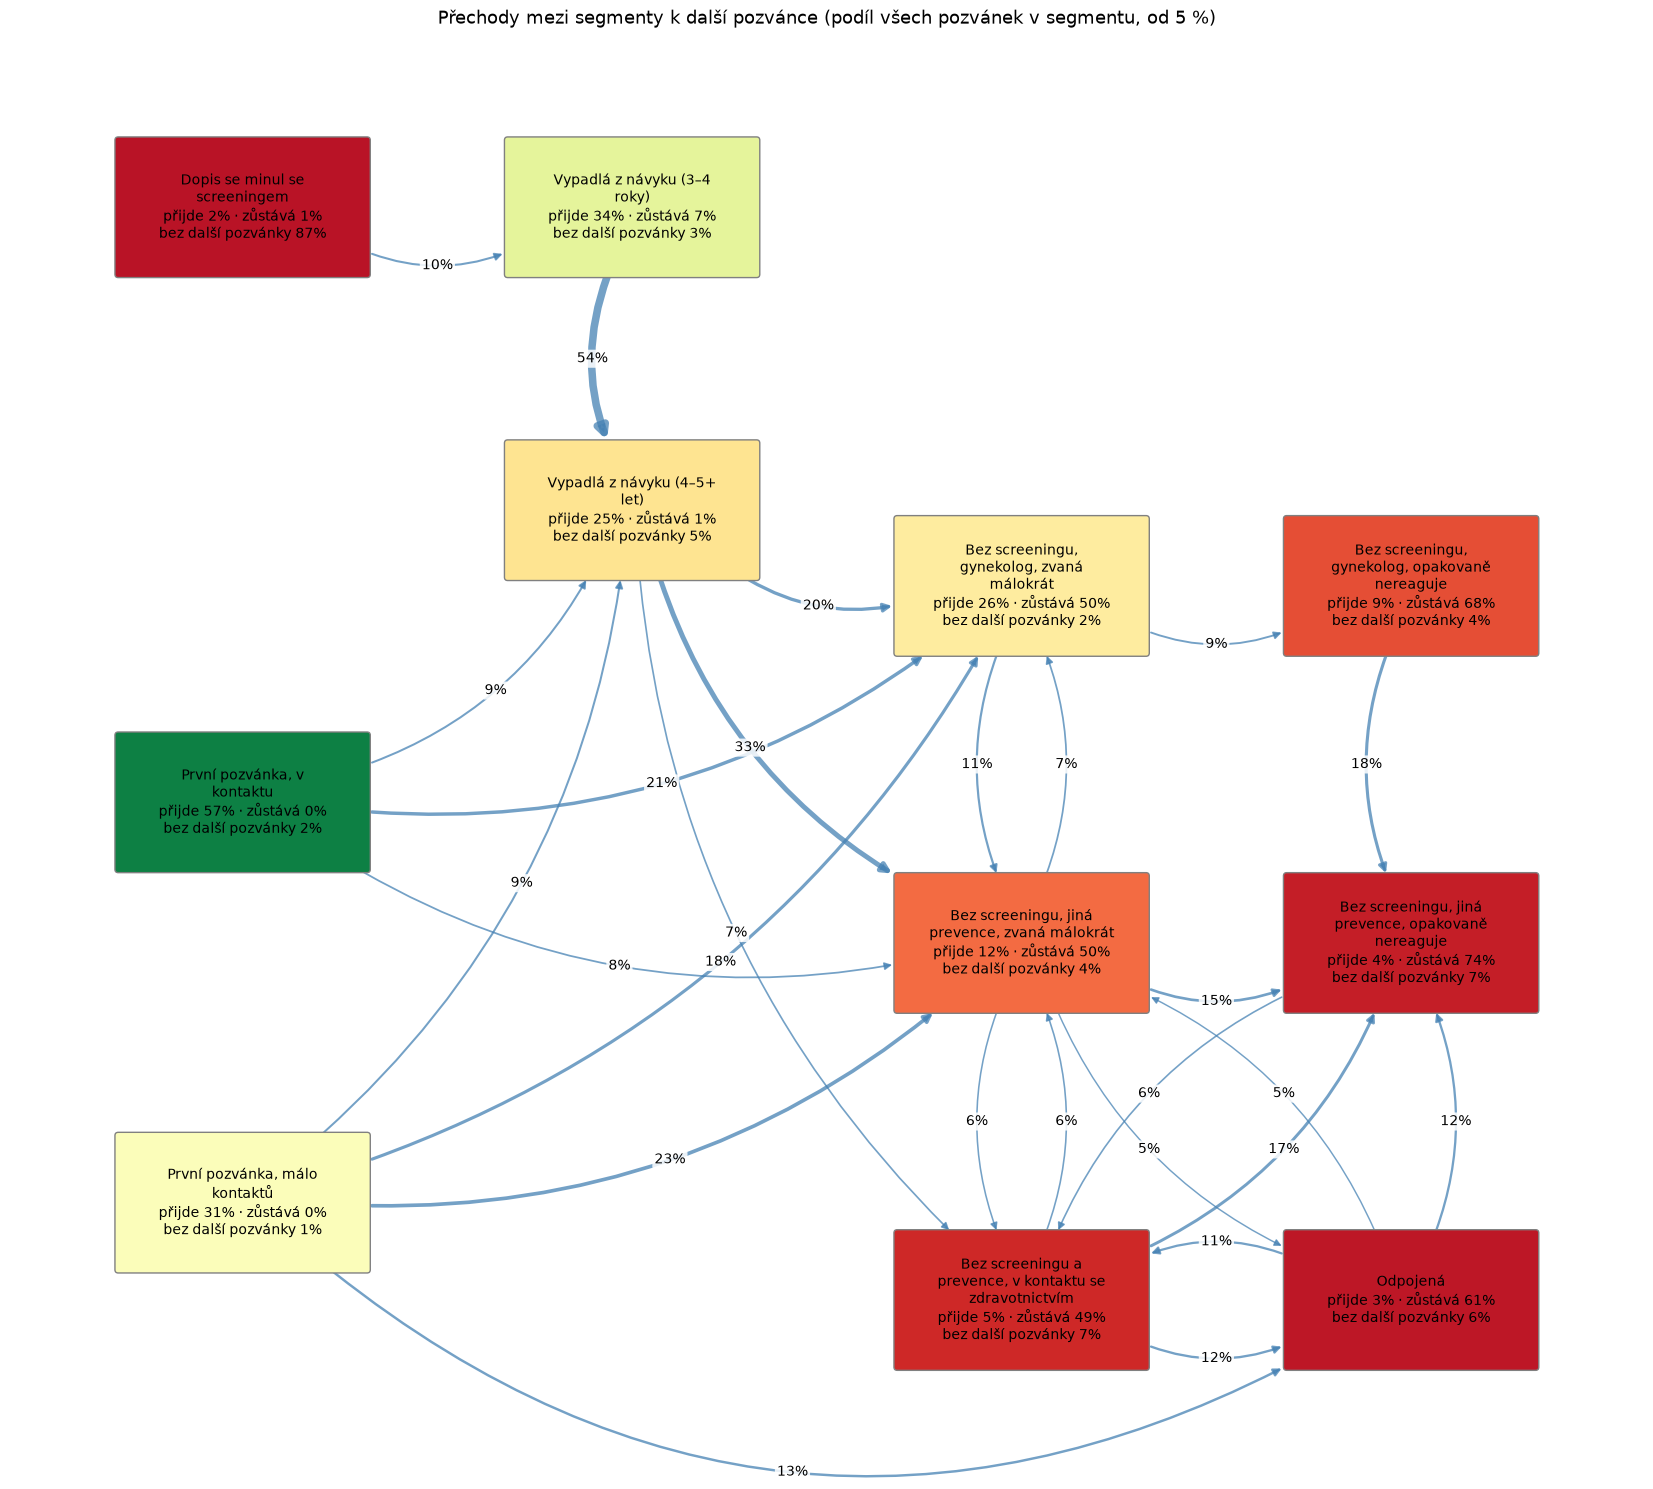

In [7]:
def kresli_graf(ax, POS, M, texty, ucast, prah, w=1.15, h=0.62, sirka=9, vynechat=(), rad_map=None, okraj_osy=0.3):
    """Uzly jako obdélníky 2w × 2h, šipky z hrany na hranu, popisek v polovině oblouku."""
    def okraj(p, smer):
        ux, uy = smer / (np.linalg.norm(smer) + 1e-9)
        t = min(w / abs(ux) if abs(ux) > 1e-9 else np.inf, h / abs(uy) if abs(uy) > 1e-9 else np.inf)
        return p + t * np.array([ux, uy]) * 1.04
    for a in M.index:
        for b in M.columns:
            v = M.loc[a, b]
            if a == b or v < prah or a not in POS or b not in POS or b in vynechat:
                continue
            p1, p2 = np.array(POS[a], float), np.array(POS[b], float)
            rad = (rad_map or {}).get((a, b), 0.18)
            dx, dy = p2 - p1
            c = (p1 + p2) / 2 + rad * np.array([dy, -dx])
            q1, q2 = okraj(p1, c - p1), okraj(p2, c - p2)
            ax.annotate("", xy=q2, xytext=q1, zorder=2,
                        arrowprops=dict(arrowstyle="-|>", color="steelblue", lw=0.6 + sirka * v, alpha=0.75,
                                        mutation_scale=10 + 10 * v, shrinkA=0, shrinkB=0,
                                        connectionstyle=f"arc3,rad={rad}"))
            ddx, ddy = q2 - q1
            lab = (q1 + q2) / 2 + 0.5 * rad * np.array([ddy, -ddx])
            ax.text(*lab, f"{v:.0%}", fontsize=10, ha="center", va="center", zorder=4,
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
    for n, (x, y) in POS.items():
        ax.add_patch(FancyBboxPatch((x - w, y - h), 2 * w, 2 * h, boxstyle="round,pad=0.03", zorder=3,
                                    fc=cmap(min(ucast.get(n, 0) / 0.6, 1)) if n in ucast else "lightgray", ec="gray"))
        ax.text(x, y, texty[n], ha="center", va="center", fontsize=10, zorder=5)
    xs, ys = zip(*POS.values())
    ax.set_xlim(min(xs) - w - okraj_osy, max(xs) + w + okraj_osy); ax.set_ylim(min(ys) - h - okraj_osy, max(ys) + h + okraj_osy)
    ax.set_aspect("equal"); ax.axis("off")

POS = {"Dopis se minul se screeningem": (0, 11), "První pozvánka, v kontaktu": (0, 5.5),
       "První pozvánka, málo kontaktů": (0, 1.8),
       "Vypadlá z návyku (3–4 roky)": (3.6, 11), "Vypadlá z návyku (4–5+ let)": (3.6, 8.2),
       "Bez screeningu, gynekolog, zvaná málokrát": (7.2, 7.5),
       "Bez screeningu, jiná prevence, zvaná málokrát": (7.2, 4.2),
       "Bez screeningu a prevence, v kontaktu se zdravotnictvím": (7.2, 0.9),
       "Bez screeningu, gynekolog, opakovaně nereaguje": (10.8, 7.5),
       "Bez screeningu, jiná prevence, opakovaně nereaguje": (10.8, 4.2),
       "Odpojená": (10.8, 0.9)}
assert set(POS) == set(NAZVY)
UC_SEG = MAT[PRISLA].to_dict()
TEXTY = {n: f"{textwrap.fill(n, 24)}\npřijde {MAT.loc[n, PRISLA]:.0%} · zůstává {MAT.loc[n, n]:.0%}\n"
            f"bez další pozvánky {MAT.loc[n, KONEC]:.0%}" for n in NAZVY}
fig, ax = plt.subplots(figsize=(19, 15))
kresli_graf(ax, POS, MAT[NAZVY], TEXTY, UC_SEG, prah=0.05, okraj_osy=1.0,
            rad_map={("První pozvánka, málo kontaktů", "Odpojená"): 0.32})
ax.set_title("Přechody mezi segmenty k další pozvánce (podíl všech pozvánek v segmentu, od 5 %)", fontsize=13)
plt.tight_layout(); plt.savefig(OUT / "graf_prechodu.png", dpi=120); plt.show()

**Jak číst.** Šipka vede ze segmentu při pozvánce do segmentu další pozvánky; číslo je podíl všech
pozvánek ve zdrojovém segmentu. V uzlu: přijde do 12 měsíců, zůstává ve stejném segmentu,
bez další pozvánky. Tok vede zleva doprava: od první pozvánky a vypadlých k segmentům bez screeningu,
z „zvaná málokrát“ k „opakovaně nereaguje“. Zpětné šipky jsou slabé.

## 6 · Zjednodušený graf: hlavní skupiny

Jedenáct segmentů sloučených do šesti skupin podle toho, co pro VZP znamenají, plus dva koncové stavy.
Podíly jsou přepočítané z počtů pozvánek (vážené velikostí segmentů); šipky od 3 %, „zůstává“ v uzlu.

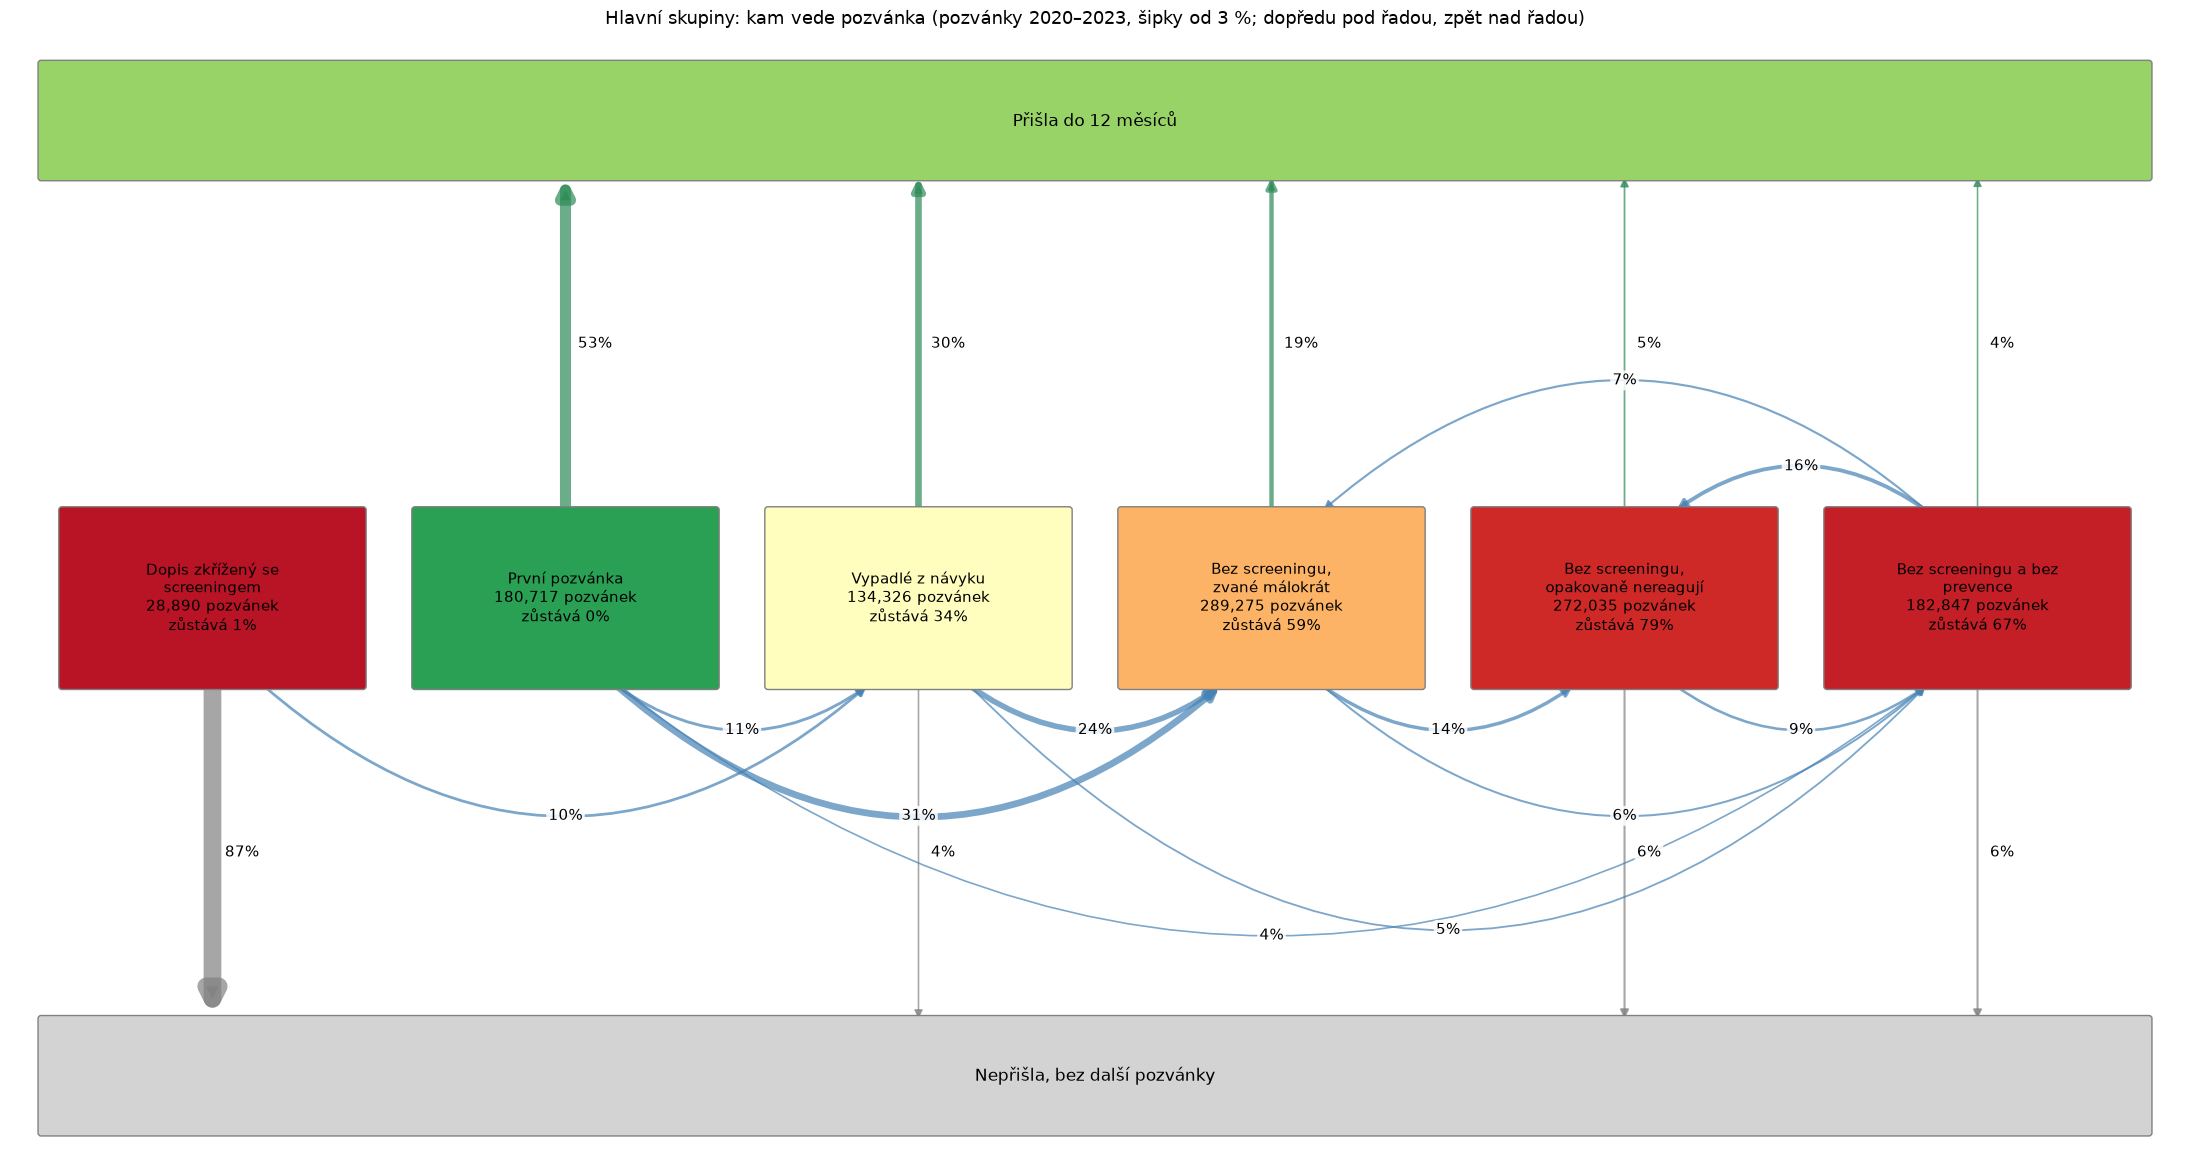

col_0,Dopis zkřížený se screeningem,První pozvánka,Vypadlé z návyku,"Bez screeningu, zvané málokrát","Bez screeningu, opakovaně nereagují",Bez screeningu a bez prevence,Přišla do 12 měsíců,"Nepřišla, bez další pozvánky"
SEGMENT,,,,,,,,
Dopis zkřížený se screeningem,1.0%,0.0%,9.8%,0.0%,0.0%,0.0%,2.4%,86.8%
První pozvánka,0.1%,0.0%,10.6%,30.5%,0.0%,4.2%,52.6%,1.9%
Vypadlé z návyku,0.1%,0.0%,33.7%,24.4%,2.7%,5.2%,30.0%,3.9%
"Bez screeningu, zvané málokrát",0.1%,0.0%,0.0%,59.0%,13.6%,6.1%,18.6%,2.7%
"Bez screeningu, opakovaně nereagují",0.0%,0.0%,0.0%,0.0%,79.5%,9.1%,5.0%,6.4%
Bez screeningu a bez prevence,0.0%,0.0%,0.0%,6.8%,15.6%,67.4%,3.9%,6.3%


In [8]:
SKUPINY = {
    "Dopis se minul se screeningem": "Dopis zkřížený se screeningem",
    "První pozvánka, v kontaktu": "První pozvánka", "První pozvánka, málo kontaktů": "První pozvánka",
    "Vypadlá z návyku (3–4 roky)": "Vypadlé z návyku", "Vypadlá z návyku (4–5+ let)": "Vypadlé z návyku",
    "Bez screeningu, gynekolog, zvaná málokrát": "Bez screeningu, zvané málokrát",
    "Bez screeningu, jiná prevence, zvaná málokrát": "Bez screeningu, zvané málokrát",
    "Bez screeningu, gynekolog, opakovaně nereaguje": "Bez screeningu, opakovaně nereagují",
    "Bez screeningu, jiná prevence, opakovaně nereaguje": "Bez screeningu, opakovaně nereagují",
    "Bez screeningu a prevence, v kontaktu se zdravotnictvím": "Bez screeningu a bez prevence",
    "Odpojená": "Bez screeningu a bez prevence",
    PRISLA: PRISLA, KONEC: KONEC}
GR = ["Dopis zkřížený se screeningem", "První pozvánka", "Vypadlé z návyku", "Bez screeningu, zvané málokrát",
      "Bez screeningu, opakovaně nereagují", "Bez screeningu a bez prevence"]
CG = CNT.T.groupby(SKUPINY).sum().T.groupby(SKUPINY).sum()
CG = CG.reindex(index=GR, columns=GR + [PRISLA, KONEC], fill_value=0)
MG = CG.div(CG.sum(axis=1), axis=0)
MG.round(4).to_csv(OUT / "prechody_skupiny.csv")

# rozložení: skupiny v řadě, nahoře široký pruh „přišla“, dole „bez další pozvánky“
GX = {n: i * 3.4 for i, n in enumerate(GR)}
GY, GW, GH = 5.0, 1.45, 0.85
TOP_Y, BOT_Y, PH = 9.6, 0.4, 0.55
fig, ax = plt.subplots(figsize=(22, 12))
x0, x1 = -GW - 0.2, GX[GR[-1]] + GW + 0.2
for yy, txt, fc in [(TOP_Y, PRISLA, cmap(0.72)), (BOT_Y, KONEC, "lightgray")]:
    ax.add_patch(FancyBboxPatch((x0, yy - PH), x1 - x0, 2 * PH, boxstyle="round,pad=0.03", fc=fc, ec="gray", zorder=3))
    ax.text((x0 + x1) / 2, yy, txt, ha="center", va="center", fontsize=12, zorder=5)
for n in GR:   # svislé šipky do koncových stavů
    x = GX[n]
    for cil, y_od, y_do in [(PRISLA, GY + GH, TOP_Y - PH), (KONEC, GY - GH, BOT_Y + PH)]:
        v = MG.loc[n, cil]
        if v >= 0.03:
            ax.annotate("", xy=(x, y_do), xytext=(x, y_od), zorder=2,
                        arrowprops=dict(arrowstyle="-|>", color="seagreen" if cil == PRISLA else "gray",
                                        lw=0.6 + 14 * v, alpha=0.7, mutation_scale=12 + 12 * v, shrinkA=0, shrinkB=0))
            ax.text(x + 0.12, (y_od + y_do) / 2, f"{v:.0%}", fontsize=11, ha="left", va="center", zorder=4,
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
for a in GR:   # oblouky mezi skupinami: dopředu pod řadou, zpět nad řadou
    for b in GR:
        v = MG.loc[a, b]
        if a == b or v < 0.03:
            continue
        xa, xb = GX[a], GX[b]
        kroky = abs(xb - xa) / 3.4
        smer = 1 if xb > xa else -1
        y_okraj = GY - GH if smer > 0 else GY + GH
        p1, p2 = (xa + smer * 0.5, y_okraj), (xb - smer * 0.5, y_okraj)
        rad = min(0.35 + 0.08 * (kroky - 1), 2.4 / (0.5 * abs(p2[0] - p1[0])))  # oblouk nejvýš 2,4 pod/nad řadou
        ax.annotate("", xy=p2, xytext=p1, zorder=2,
                    arrowprops=dict(arrowstyle="-|>", color="steelblue", lw=0.6 + 14 * v, alpha=0.7,
                                    mutation_scale=12 + 12 * v, shrinkA=0, shrinkB=0, connectionstyle=f"arc3,rad={rad}"))
        dx = p2[0] - p1[0]
        ax.text((p1[0] + p2[0]) / 2, y_okraj - 0.5 * rad * dx, f"{v:.0%}", fontsize=11, ha="center", va="center", zorder=4,
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
for n in GR:
    ax.add_patch(FancyBboxPatch((GX[n] - GW, GY - GH), 2 * GW, 2 * GH, boxstyle="round,pad=0.03", zorder=3,
                                fc=cmap(min(MG.loc[n, PRISLA] / 0.6, 1)), ec="gray"))
    ax.text(GX[n], GY, f"{textwrap.fill(n, 20)}\n{CG.loc[n].sum():,} pozvánek\nzůstává {MG.loc[n, n]:.0%}",
            ha="center", va="center", fontsize=10.5, zorder=5)
ax.set_xlim(x0 - 0.3, x1 + 0.3); ax.set_ylim(BOT_Y - PH - 0.3, TOP_Y + PH + 0.3); ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Hlavní skupiny: kam vede pozvánka (pozvánky 2020–2023, šipky od 3 %; "
             "dopředu pod řadou, zpět nad řadou)", fontsize=13)
plt.tight_layout(); plt.savefig(OUT / "graf_skupin.png", dpi=120); plt.show()
MG.style.format("{:.1%}")

**Jak číst.** Šest skupin v řadě, nahoře pás „přišla“, dole „bez další pozvánky“. Oblouky pod řadou
vedou doprava (k horším skupinám), nad řadou zpět. Hlavní tok: první pozvánka (53 % přijde) → 31 % do
„zvané málokrát“ (59 % zůstává, 19 % přijde) → 14 % do „opakovaně nereagují“ (79 % zůstává, 5 % přijde).
Jediné výraznější zpětné šipky vedou z „bez screeningu a bez prevence“ (16 % a 7 %).

## 7 · Hlavní zjištění

1. **Segmenty jsou dobrý a stabilní model.** Účast segmentu z let 2020–2023 seřadí ženy pozvané v roce 2024
   s AUROC **0,807** do 12 měsíců (0,801 do 3 měsíců); model hazardu z 19 sloupců má 0,836. Průměr
   předpovědi (17,8 %) je pod skutečností 2024 (19,2 %), protože účast mezi lety mírně roste.
2. **Účast se mezi segmenty liší 25×:** od 2,4 % (dopis se minul se screeningem) po 59,6 % (první
   pozvánka, v kontaktu se zdravotnictvím).
3. **V roce 2024 nepřišlo 207 tisíc žen.** Největší skupina je „jiná prevence, opakovaně nereaguje“
   (56,8 tis., 27 % nepřišlých), následují „jiná prevence, zvaná málokrát“ (25,7 tis.) a odpojené (23,6 tis.).
4. **Segmenty bez screeningu jsou lepkavé.** Při další pozvánce zůstává ve stejném segmentu 49–74 %
   všech pozvaných. Ve skupinách: ze „zvaných málokrát“ zůstává 59 % a 14 % sestoupí mezi nereagující;
   z nereagujících zůstává 79 % a přijde 5 %.
5. **První pozvánka rozhoduje.** Přijde 53 % žen (57 % v kontaktu se zdravotnictvím, 31 % s málo kontakty).
   Ze všech prvních pozvánek 31 % přejde příští rok do „bez screeningu, zvané málokrát“.
6. **Zkřížené dopisy:** 7 600 žen v roce 2024 dostalo dopis 0–1 měsíc po screeningu. Účast 2,4 %,
   87 % další pozvánku v datech nemá.
7. **Rozptyl uvnitř segmentů** (model hazardu, p10–p90) je široký jen u prvních pozvánek (6–64 % a 32–78 %),
   vypadlých a žen u gynekologa. U nereagujících a odpojených je úzký a nízký (1–7 %). AUROC uvnitř
   segmentů je 0,61–0,79.
8. **Early stopping vybral 750 iterací modelu hazardu**, stejně jako pevné nastavení v
   `vzp_segmentation_final.ipynb`. Srovnání s modelem hazardu je proto v obou verzích stejné.

## 8 · Návrhy experimentů

Segmenty říkají, kdo přijde sám, ne kdo přijde **díky** zásahu. To ukáže jen randomizovaný
experiment. Návrhy vycházejí z intervencí seřazených podle očekávaného přínosu v
`docs/interventions.md`; jako nejmenší detekovaný účinek (MDE) je spodní hranice očekávaného
přínosu. Výpočet velikosti vzorku: dva podíly, oboustranný test, α = 0,05, síla 80 %, základní účast
= skutečnost 2024 ve vybraných segmentech. U experimentu přes gynekology (randomizace po ordinacích)
je velikost vynásobená předpokládaným design efektem 2.

In [9]:
def n_na_rameno(p0, mde, alfa=0.05, sila=0.8):
    p1 = p0 + mde
    pb = (p0 + p1) / 2
    za, zb = norm.ppf(1 - alfa / 2), norm.ppf(sila)
    return int(np.ceil((za * np.sqrt(2 * pb * (1 - pb)) + zb * np.sqrt(p0 * (1 - p0) + p1 * (1 - p1))) ** 2 / mde ** 2))

NEJTEZSI = ["nikdy_prevence_nereaguje", "nikdy_gynekolog_nereaguje", "nikdy_kontakt", "odpojena"]
EXP = [
    ("E1", "Předrezervovaný termín místo otevřené pozvánky", "standardní dopis",
     test.SEG.isin(["prvni_pozvanka", "prvni_pozvanka_malo_kontaktu", "vypadla_3_4"]), "6M", 0.05, 1),
    ("E2", "Telefonická navigace při první pozvánce bez kontaktu se zdravotnictvím", "standardní dopis",
     test.SEG.eq("prvni_pozvanka_malo_kontaktu"), "12M", 0.05, 1),
    ("E3", "Seznamy žen bez mamografu pro gynekology (audit a zpětná vazba)", "běžná péče",
     test.SEG.isin(["nikdy_gynekolog_malo_zvana", "nikdy_gynekolog_nereaguje"]), "12M", 0.02, 2),
    ("E4", "SMS s odkazem na objednání navíc k dopisu", "jen dopis",
     test.SEG.eq("nikdy_prevence_malo_zvana"), "6M", 0.02, 1),
    ("E5", "Změna kanálu před 7. pozvánkou (telefonát místo dopisu)", "dopis",
     test.SEG.isin(["nikdy_gynekolog_malo_zvana", "nikdy_prevence_malo_zvana"]) & test.PRIOR_INVITATION_COUNT.between(4, 6),
     "12M", 0.02, 1),
    ("E6", "Navigace a balík opatření pro nejtěžší skupiny", "dopis",
     test.SEG.isin(NEJTEZSI), "12M", 0.03, 1),
    ("E7", "Kolik přináší samotný roční dopis (dopis jednou za 2 roky)", "dopis každý rok",
     test.SEG.isin(NEJTEZSI), "12M", -0.015, 1),
]
rows = []
for kod, zasah, kontrola, maska, h, mde, deff in EXP:
    p0 = test.loc[maska, LABELS[HOR.index(h)]].mean()
    n = n_na_rameno(p0, mde) * deff
    rows.append({"experiment": kod, "zásah": zasah, "kontrola": kontrola, "výstup": f"účast do {h}",
                 "žen za rok (2024)": int(maska.sum()), "základní účast": p0, "MDE (body)": mde * 100,
                 "design efekt": deff, "žen na rameno": n, "podíl ročního počtu (2 ramena)": 2 * n / maska.sum()})
EXPT = pd.DataFrame(rows).set_index("experiment")
EXPT.to_csv(OUT / "experimenty_velikost_vzorku.csv")
EXPT.style.format({"žen za rok (2024)": "{:,}", "základní účast": "{:.1%}", "MDE (body)": "{:+.1f}",
                   "žen na rameno": "{:,}", "podíl ročního počtu (2 ramena)": "{:.0%}"})

,zásah,kontrola,výstup,žen za rok (2024),základní účast,MDE (body),design efekt,žen na rameno,podíl ročního počtu (2 ramena)
experiment,,,,,,,,,
E1,Předrezervovaný termín místo otevřené pozvánky,standardní dopis,účast do 6M,"53,627",34.5%,+5.0,1,"1,463",5%
E2,Telefonická navigace při první pozvánce bez kontaktu se zdravotnictvím,standardní dopis,účast do 12M,"7,127",35.7%,+5.0,1,"1,482",42%
E3,Seznamy žen bez mamografu pro gynekology (audit a zpětná vazba),běžná péče,účast do 12M,"51,047",20.5%,+2.0,2,"13,254",52%
E4,SMS s odkazem na objednání navíc k dopisu,jen dopis,účast do 6M,"29,487",7.0%,+2.0,1,"2,872",19%
E5,Změna kanálu před 7. pozvánkou (telefonát místo dopisu),dopis,účast do 12M,"36,294",14.3%,+2.0,1,"5,095",28%
E6,Navigace a balík opatření pro nejtěžší skupiny,dopis,účast do 12M,"122,244",5.6%,+3.0,1,"1,145",2%
E7,Kolik přináší samotný roční dopis (dopis jednou za 2 roky),dopis každý rok,účast do 12M,"122,244",5.6%,-1.5,1,"3,198",5%


**Jak číst.** „Žen na rameno“ je počet pro zadaný účinek (MDE) při α = 0,05 a síle 80 %, u E3 vynásobený
design efektem 2. Poslední sloupec ukazuje, jakou část ročního počtu žen v cílových segmentech pokus
se dvěma rameny spotřebuje. **Všech sedm pokusů se vejde do jednoho ročníku pozvánek.**

* **E1 Předrezervovaný termín** (první pozvánky a vypadlé 3–4 roky, 53,6 tis. žen ročně, účast do 6M 34,5 %):
  pro +5 p. b. stačí 1 463 žen na rameno, 5 % ročníku. Lze začít malým pilotem.
* **E2 Telefonická navigace** (první pozvánka s málo kontakty, 7,1 tis. žen, 35,7 %): 1 482 na rameno,
  42 % ročníku. Malý segment, pokus musí zahrnout skoro polovinu žen.
* **E3 Seznamy pro gynekology** (ženy u gynekologa bez screeningu, 51,0 tis., 20,5 %): pro +2 p. b.
  s randomizací po ordinacích 13 254 na rameno, **52 % ročníku**. Nejnáročnější pokus; design efekt
  je předpoklad, skutečný ICC je třeba odhadnout.
* **E4 SMS navíc k dopisu** (jiná prevence, zvaná málokrát, 29,5 tis., 7,0 % do 6M): 2 872 na rameno, 19 %.
* **E5 Změna kanálu před 7. pozvánkou** (zvané málokrát se 4–6 dřívějšími pozvánkami, 36,3 tis., 14,3 %):
  5 095 na rameno, 28 %. Cílem je zastavit sestup do „opakovaně nereaguje“.
* **E6 Navigace a balík opatření** (čtyři nejtěžší segmenty, 122,2 tis., 5,6 %): pro +3 p. b. stačí 1 145
  na rameno, 2 % ročníku.
* **E7 Dopis jednou za 2 roky** (stejné segmenty): pro −1,5 p. b. 3 198 na rameno, 5 %. Počítáno jako
  oboustranný test; pro skutečnou non-inferioritu je třeba zvolit hranici a počet přepočítat.
  Vyžaduje právní a etické posouzení.

## Poznámky a omezení

* **Segmenty popisují, kdo přijde sám, ne kdo přijde díky zásahu.** Páky v pravidlech jsou hypotézy.
* **„Přišla“ = mamografie nebo dovyšetření do 12 měsíců po pozvánce** (kódy 89178, 89223, 89225,
  89314, 89510, 89814).
* **„Bez screeningu“ = bez kódu za posledních 5 let**: ženy z „Vypadlé z návyku (4–5+ let)“ se do
  segmentů bez screeningu přesouvají i jen proto, že jejich screening vypadne z okna.
* **Prahy pravidel** (6 pozvánek, 6 kontaktů, 24 a 48 měsíců) jsou zvolené podle rozložení dat let
  2020–2023, ne optimalizované.
* **V datech nejsou nově pojištěné ženy** (jen nepřetržitě pojištěné 2015–2025) ani ženy 75+;
  územní pracoviště VZP není okres.
* **Velikosti vzorků jsou orientační**: design efekt pro randomizaci po ordinacích je předpoklad,
  experiment s řidším zváním (E7) potřebuje právní a etické posouzení.